# 05 — Model Training
**Part D | Milestone 5**

Question: which regression models can predict a window's drift `err_mag_m` from its 104 IMU features, and how do we train and tune them **without ever touching the test flight**?

This notebook **calls** the code in `src/vio_drift/models/ml/` (no logic is re-implemented here):

| Module | Role |
|---|---|
| `data.py` | one table: features + target, split by fold |
| `models.py` | mean baseline, OLS, Ridge, Lasso |
| `tuning.py` | time-block CV that picks Ridge/Lasso's `alpha` on the training flight |
| `train.py` | tune (if needed) then fit — the same function `scripts/train_eval.py` uses |

Held-out scoring and error analysis are in notebook 06.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, display

from vio_drift.data.splits import load_splits
from vio_drift.features.build_features import feature_names
from vio_drift.models.ml.data import load_dataset, fold_frames
from vio_drift.models.ml.models import MODELS
from vio_drift.models.ml.tuning import time_block_splits, tune_alpha, GAP_WINDOWS
from vio_drift.models.ml.train import fit_model

ROOT = Path.cwd().parent
FIG = ROOT / "figures" / "ml"
FIG.mkdir(parents=True, exist_ok=True)
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
processed = ROOT / config["data"]["processed_dir"]
sequences = config["data"]["sequences"]
FEATS = feature_names()
TARGET = "err_mag_m"
print("sequences:", sequences, "| window:", config["windowing"]["window_seconds"], "s")

sequences: ['MH_01_easy', 'MH_02_easy'] | window: 2.0 s


## 1. The training table

One row per 2 s window: its flight, id, start time, the 104 Part C features and the target. Rows stay in time order — the tuning in Section 5 depends on it.

In [ ]:
df = load_dataset(processed, sequences, target=TARGET)
print("table:", df.shape, "| missing values:", int(df.isna().sum().sum()))
df.groupby("seq_id")[TARGET].describe()[["count", "mean", "std", "min", "max"]].round(3)

table: (1312, 108) | missing values: 0


,count,mean,std,min,max
seq_id,,,,,
MH_01_easy,720.0,1.215,0.058,1.002,1.336
MH_02_easy,592.0,1.203,0.079,0.894,1.320


The drift is about **1.2 m** per window on both flights, but varies by only **6–8 cm** around that. So "always guess 1.2 m" is already close — every model has to beat that mean baseline, and R² (how much of the 6–8 cm variation is explained) is the fairer score.

## 2. Folds: train on one flight, test on the other

Windows overlap by 87.5%, so a random row split would leak nearly identical windows into the test set. We use leave-one-sequence-out from `splits.json`. With two flights that is two folds.

In [ ]:
folds = load_splits(processed / "splits.json")
rows = []
for fold in folds:
    train, test = fold_frames(df, fold)
    assert not set(train["seq_id"]) & set(test["seq_id"])
    rows.append({"fold": fold.fold_id, "train": fold.train[0], "n_train": len(train),
                 "test": fold.test[0], "n_test": len(test)})
pd.DataFrame(rows)

,fold,train,n_train,test,n_test
0,leave_MH_01_easy,MH_02_easy,592,MH_01_easy,720
1,leave_MH_02_easy,MH_01_easy,720,MH_02_easy,592


## 3. The models

| Model | Idea | Tuned |
|---|---|---|
| `mean` | predict the training flight's mean drift | — |
| `ols` | linear regression, least squares | — |
| `ridge` | OLS + L2 penalty $\alpha\lVert w\rVert_2^2$: shrinks all weights | `alpha` |
| `lasso` | OLS + L1 penalty $\alpha\lVert w\rVert_1$: sets weak weights to exactly 0 | `alpha` |

The linear models standardise the features first (mean 0, std 1) inside a pipeline. The penalties treat every weight the same, so features must be on one scale — raw `az_mean` is ≈ 9.8 while a correlation lies in [−1, 1]. Because the scaler is part of the pipeline, its mean and std come from the training flight only.

In [ ]:
for name, spec in MODELS.items():
    grid = "—" if spec.alphas is None else f"{len(spec.alphas)} values, {spec.alphas[0]:g} … {spec.alphas[-1]:g}"
    print(f"{name:6s} alpha grid: {grid}")

mean   alpha grid: —
ols    alpha grid: —
ridge  alpha grid: 17 values, 0.001 … 100000
lasso  alpha grid: 16 values, 1e-06 … 0.1


## 4. Why plain OLS is not enough

OLS has 105 parameters, only 592–720 training windows, and many near-duplicate features (`_var` = `_std`², 22 pairs with |r| > 0.95). It fits the training flight much better than any new flight — the classic sign of over-fitting.

The sweep below (`scripts/alpha_sweep.py`) fits Ridge and Lasso at every `alpha` and scores **both** flights. It uses the test flight, so it is a **diagnostic only** — it shows the shape of the bias–variance curve, but we must not pick `alpha` from it.

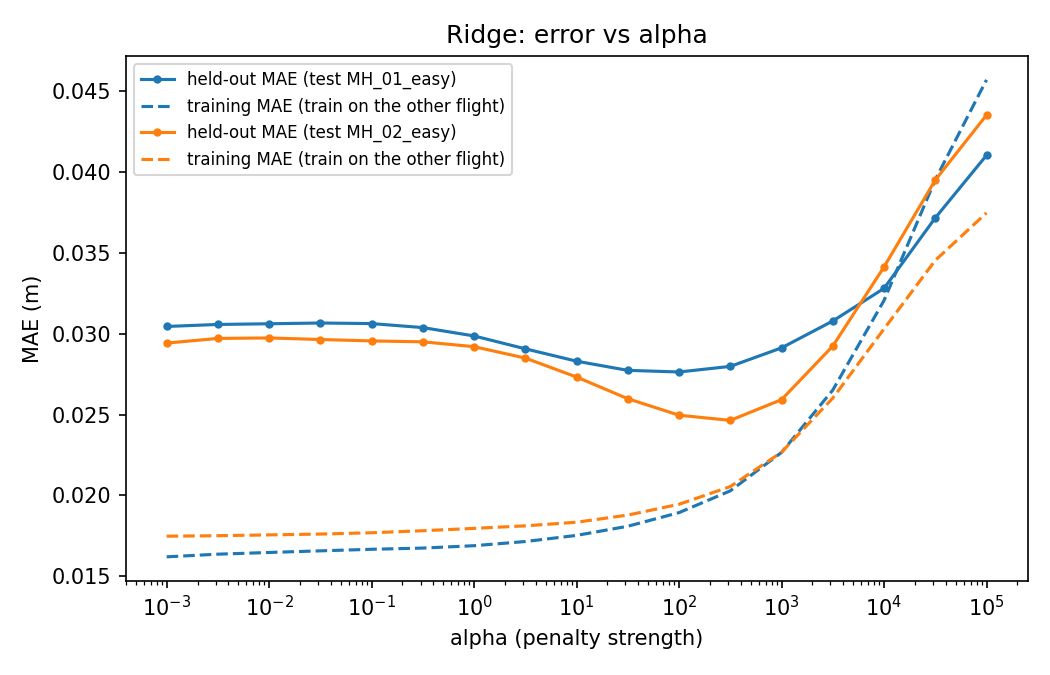

In [ ]:
display(Image(FIG / "alpha_sweep_ridge.png", width=620))

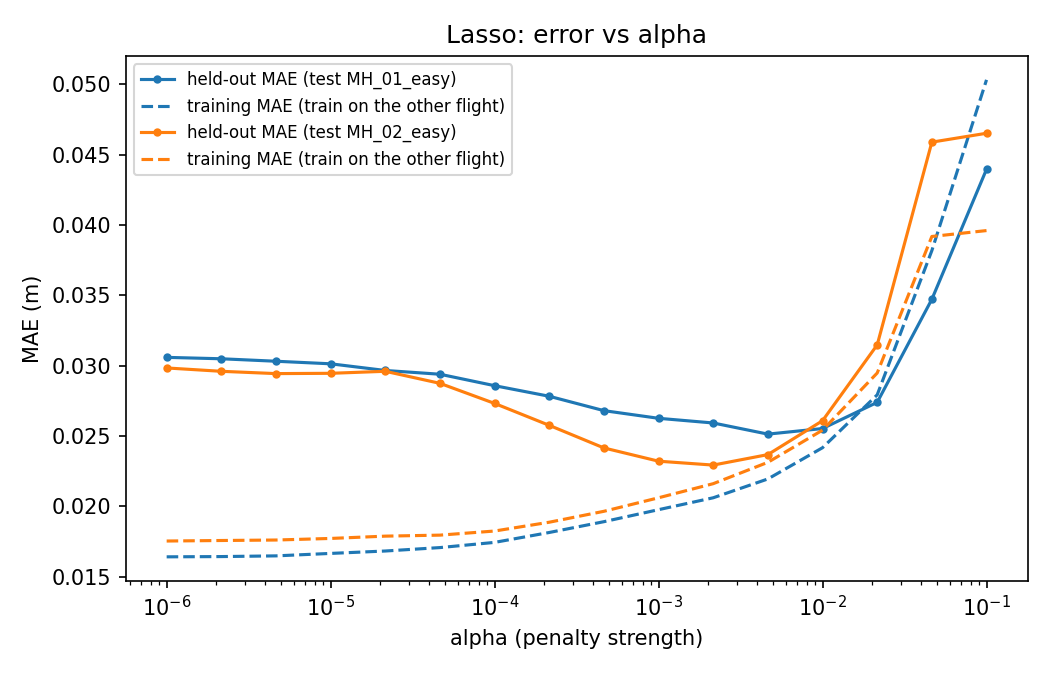

In [ ]:
display(Image(FIG / "alpha_sweep_lasso.png", width=620))

In [ ]:
sweep = pd.read_csv(ROOT / "results" / "diagnostics" / f"alpha_sweep_{TARGET}.csv")
best = sweep.loc[sweep.groupby(["model", "test_seq"])["mae"].idxmin(),
                 ["model", "test_seq", "alpha", "mae", "train_mae", "n_nonzero"]]
best.round(4)

,model,test_seq,alpha,mae,train_mae,n_nonzero
28,lasso,MH_01_easy,0.0046,0.0251,0.0220,12
60,lasso,MH_02_easy,0.0022,0.0229,0.0216,19
10,ridge,MH_01_easy,100.0000,0.0276,0.0189,104
44,ridge,MH_02_easy,316.2278,0.0246,0.0205,104


Left side of each curve: tiny `alpha` ≈ OLS — training error low, held-out error high (over-fitting). Right side: huge `alpha` pushes every weight to 0 — the model becomes the mean baseline (under-fitting). The held-out minimum sits in the middle, at about the same `alpha` for both flights, and Lasso reaches it keeping only ~10–30 of the 104 features.

## 5. Choosing `alpha` from the training flight only: time-block CV

Each fold has one training flight, so there is no second flight to validate on. We cut the training flight into **5 contiguous time blocks**. Each block is scored once by a model trained on the other four. Training rows within **16 windows (4 s)** of the scored block are dropped, so no training window shares an IMU sample with a scored one. A random k-fold would put overlapping neighbours on both sides and reward memorising.

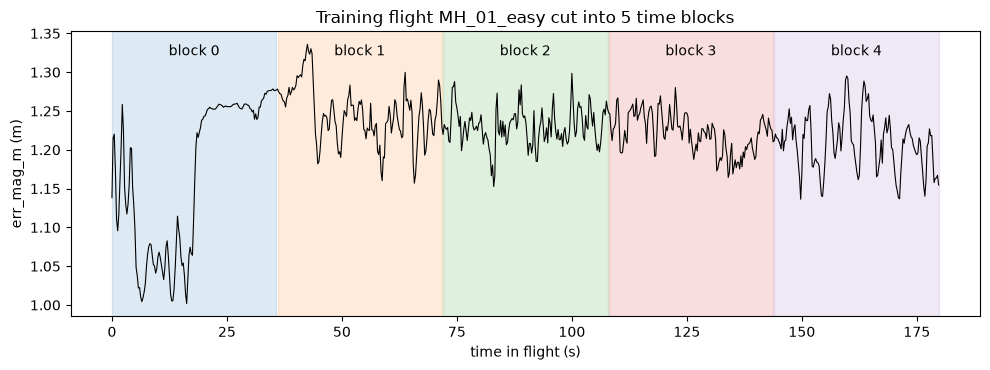

In [ ]:
fold = folds[1]                                    # train on MH_01_easy
train, _ = fold_frames(df, fold)
splits = time_block_splits(len(train), n_blocks=5, gap_windows=GAP_WINDOWS)
t = (train["t_start_ns"] - train["t_start_ns"].iloc[0]) / 1e9

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, train[TARGET], lw=0.8, color="black")
for i, (_, block) in enumerate(splits):
    ax.axvspan(t.iloc[block[0]], t.iloc[block[-1]], alpha=0.15, color=f"C{i}")
    ax.text(t.iloc[block].mean(), train[TARGET].max(), f"block {i}", ha="center", va="top")
ax.set_xlabel("time in flight (s)"); ax.set_ylabel("err_mag_m (m)")
ax.set_title(f"Training flight {fold.train[0]} cut into 5 time blocks")
fig.tight_layout(); fig.savefig(FIG / f"cv_blocks_{fold.train[0]}.png", dpi=150); plt.show()

Block 0 is the **take-off**: the drift is lower and swings 3–4× more than in the rest of the flight.

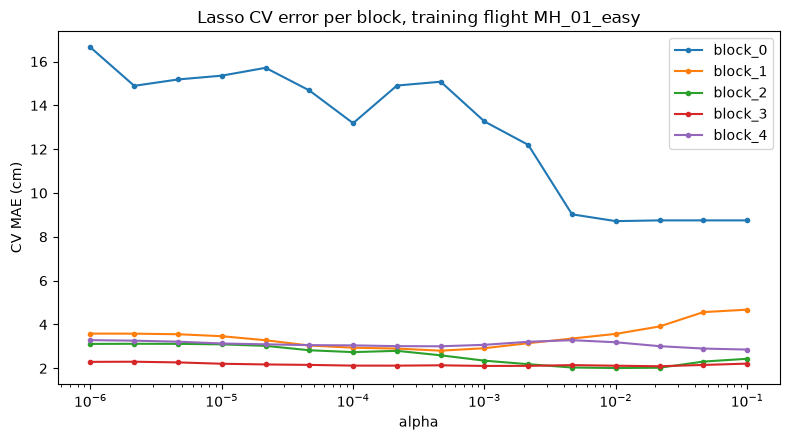

,mean_mae,block_0,block_1,block_2,block_3,block_4
alpha,,,,,,
0.000001,5.79,16.65,3.58,3.11,2.29,3.29
0.000002,5.43,14.89,3.58,3.12,2.30,3.26
0.000005,5.47,15.18,3.56,3.12,2.27,3.22
0.000010,5.45,15.36,3.46,3.09,2.21,3.13
0.000022,5.46,15.71,3.28,3.03,2.18,3.10
0.000046,5.15,14.68,3.04,2.82,2.16,3.06
0.000100,4.81,13.19,2.94,2.74,2.12,3.05
0.000215,5.15,14.90,2.90,2.80,2.12,3.01
0.000464,5.12,15.08,2.81,2.59,2.14,3.01


In [ ]:
res = tune_alpha(MODELS["lasso"].build, MODELS["lasso"].alphas,
                 train[FEATS], train[TARGET], n_blocks=5)
blocks = res.cv_table.filter(like="block_")

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, col in enumerate(blocks.columns):
    ax.plot(res.cv_table["alpha"], blocks[col] * 100, marker="o", ms=3, color=f"C{i}", label=col)
ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("CV MAE (cm)")
ax.set_title(f"Lasso CV error per block, training flight {fold.train[0]}")
ax.legend(); fig.tight_layout()
fig.savefig(FIG / f"cv_block_errors_lasso_{fold.train[0]}.png", dpi=150); plt.show()

(res.cv_table.set_index("alpha").drop(columns="se_mae") * 100).round(2)

When block 0 is scored, the model was trained on blocks 1–4 only and has **never seen a take-off**, so it misses by 9–17 cm while the other blocks sit at 2–4 cm. That one block dominates the *mean* CV error, and the mean is smallest at large `alpha` (predict ≈ the average). The final model, though, trains on the whole flight *including* take-off, so block 0's score is unrepresentative.

**Rule we use: pick the `alpha` with the lowest *median* block error**, so one unrepresentative block cannot decide alone.

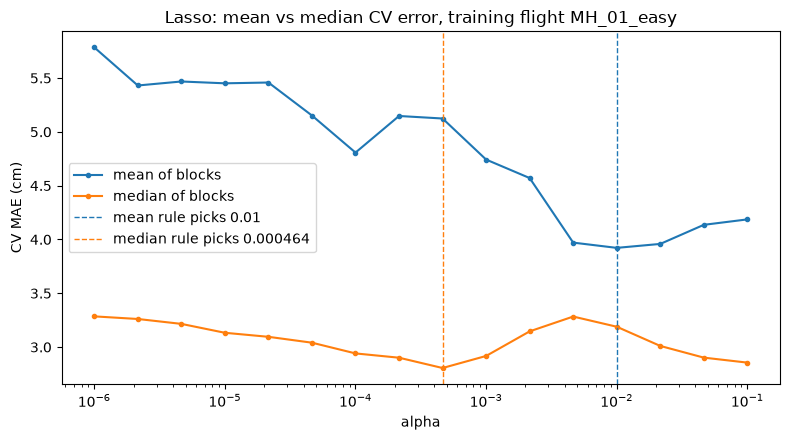

In [ ]:
median = blocks.median(axis=1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(res.cv_table["alpha"], res.cv_table["mean_mae"] * 100, marker="o", ms=3, label="mean of blocks")
ax.plot(res.cv_table["alpha"], median * 100, marker="o", ms=3, label="median of blocks")
ax.axvline(res.best_alpha, color="C0", ls="--", lw=1, label=f"mean rule picks {res.best_alpha:.3g}")
ax.axvline(res.median_alpha, color="C1", ls="--", lw=1, label=f"median rule picks {res.median_alpha:.3g}")
ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("CV MAE (cm)")
ax.set_title(f"Lasso: mean vs median CV error, training flight {fold.train[0]}")
ax.legend(); fig.tight_layout()
fig.savefig(FIG / f"cv_rule_lasso_{fold.train[0]}.png", dpi=150); plt.show()

The median curve is bumpy too, and at the largest `alpha` it nearly comes back down to its minimum: with a single training flight, any CV estimate is noisy. The median rule is *more robust* than the mean, not perfect — which is why we checked its picks against the sweep below.

`scripts/tuning_check.py` compared the rules (mean, 1-standard-error, median) and 3/5/8/10 blocks on both folds. The median rule with ≥ 5 blocks landed in the good part of the sweep every time; the mean and 1-SE rules sometimes chose an `alpha` that zeroes every Lasso weight.

In [ ]:
check = pd.read_csv(ROOT / "results" / "diagnostics" / f"tuning_check_{TARGET}.csv")
five = check[check["n_blocks"] == 5]
pd.concat({"alpha": five.pivot_table(index=["model", "rule"], columns="test_seq", values="alpha").map(lambda a: f"{a:.3g}"),
           "held-out R²": five.pivot_table(index=["model", "rule"], columns="test_seq", values="test_r2").round(3)},
          axis=1)

alpha            held-out R²           
test_seq     MH_01_easy MH_02_easy  MH_01_easy MH_02_easy
model rule                                               
lasso 1se       0.00215        0.1       0.676     -0.022
      best      0.00215       0.01       0.676      0.801
      median    0.00215   0.000464       0.676      0.837
ridge 1se         1e+03      1e+05       0.603      0.130
      best          100   3.16e+04       0.639      0.324
      median        316       31.6       0.631      0.803

## 6. Train the final models

For every fold and model: tune `alpha` (Ridge, Lasso) with the 5-block median rule on the training flight, then refit on the **whole** training flight. `fit_model` is the same function `scripts/train_eval.py` uses.

In [ ]:
fitted = {}
rows = []
for fold in folds:
    train, _ = fold_frames(df, fold)
    for name in MODELS:
        fm = fit_model(name, train[FEATS], train[TARGET])
        fitted[(fold.fold_id, name)] = fm
        rows.append({"train_flight": fold.train[0], "model": name, "alpha": fm.alpha})
chosen = pd.DataFrame(rows).pivot(index="model", columns="train_flight", values="alpha").reindex(list(MODELS))
chosen

train_flight,MH_01_easy,MH_02_easy
model,,
mean,NaN,NaN
ols,NaN,NaN
ridge,31.622777,316.227766
lasso,0.000464,0.002154


Both chosen `alpha` values per model sit inside the low part of the sweep curves in Section 4, even though they were picked without the test flight.

## 7. What Lasso keeps

Lasso sets most weights to exactly zero. The bars show the surviving weights on standardised features (change in predicted drift, in metres, per one-standard-deviation change of the feature).

train MH_02_easy: 18 of 104 features kept


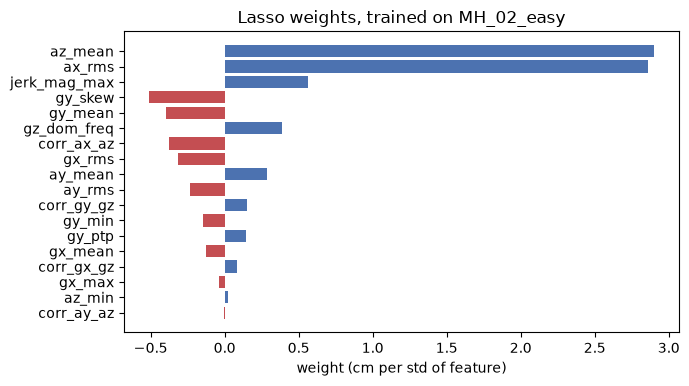

train MH_01_easy: 40 of 104 features kept


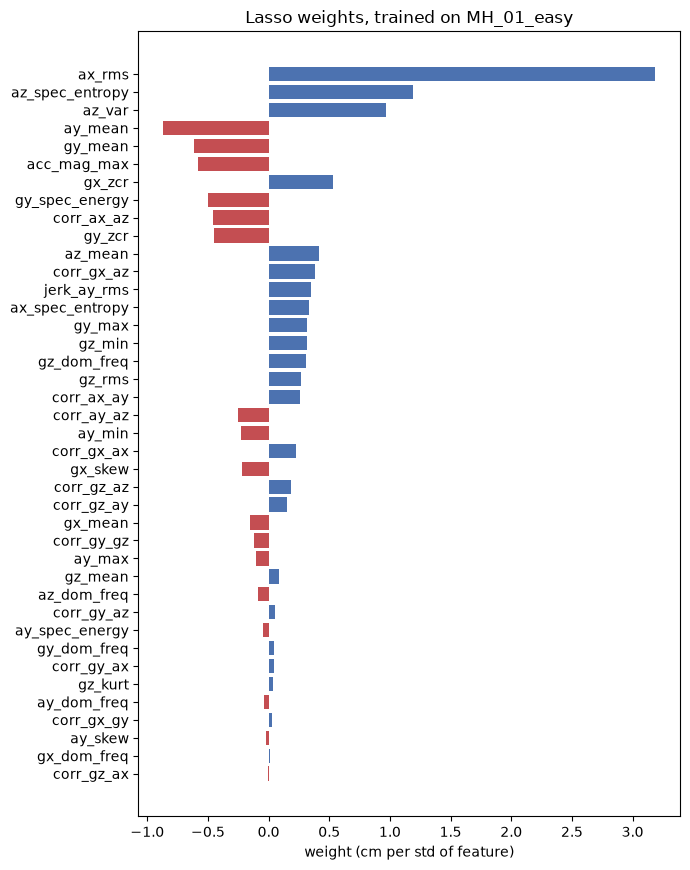

In [ ]:
for fold in folds:
    model = fitted[(fold.fold_id, "lasso")].model
    coef = pd.Series(model.named_steps["model"].coef_, index=FEATS)
    kept = coef[coef != 0].sort_values(key=np.abs)
    print(f"train {fold.train[0]}: {len(kept)} of {len(FEATS)} features kept")

    fig, ax = plt.subplots(figsize=(7, max(3, 0.22 * len(kept))))
    ax.barh(kept.index, kept.values * 100, color=["#C44E52" if v < 0 else "#4C72B0" for v in kept.values])
    ax.set_xlabel("weight (cm per std of feature)")
    ax.set_title(f"Lasso weights, trained on {fold.train[0]}")
    fig.tight_layout(); fig.savefig(FIG / f"lasso_coefficients_{fold.train[0]}.png", dpi=150); plt.show()

In [ ]:
kept_sets = [set(np.array(FEATS)[fitted[(f.fold_id, "lasso")].model.named_steps["model"].coef_ != 0])
             for f in folds]
print("kept by both folds:", ", ".join(sorted(str(f) for f in kept_sets[0] & kept_sets[1])))

kept by both folds: ax_rms, ay_mean, az_mean, corr_ax_az, corr_ay_az, corr_gy_gz, gx_mean, gy_mean, gz_dom_freq


## Summary

- Input: 104 IMU features per 2 s window; target `err_mag_m` (≈ 1.2 m, varying by 6–8 cm).
- Split: leave-one-flight-out — train on MH_02, test on MH_01, and the reverse.
- Models: mean baseline, OLS, Ridge, Lasso; features standardised on the training flight.
- OLS over-fits (104 correlated features, ~600 windows); the L2/L1 penalties fix that.
- `alpha` is chosen on the training flight only, by 5-block time CV with a 4 s gap and the **median** rule (the take-off block otherwise dominates).
- Lasso keeps only 18 (trained on MH_02) and 40 (trained on MH_01) of the 104 features; 9 are kept by both, including the accelerometer means and RMS (tilt against gravity).

Next: notebook 06 scores these models on the held-out flights.